In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load data
data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

df = data[(data['store'] == 1) & (data['item'] == 1)].copy()
df = df.sort_values('date')

# Create rolling mean feature (7-day)
df['rolling_7'] = df['sales'].rolling(window=7).mean()

# Drop initial NaN rows
df = df.dropna()

# Time-aware split
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
valid = df.iloc[split_index:]


In [2]:
valid['rolling_forecast'] = df['rolling_7'].iloc[split_index:]


In [3]:
mae = mean_absolute_error(valid['sales'], valid['rolling_forecast'])
rmse = np.sqrt(mean_squared_error(valid['sales'], valid['rolling_forecast']))

print("Rolling Mean MAE:", mae)
print("Rolling Mean RMSE:", rmse)


Rolling Mean MAE: 4.2570643642072215
Rolling Mean RMSE: 5.351016905616936


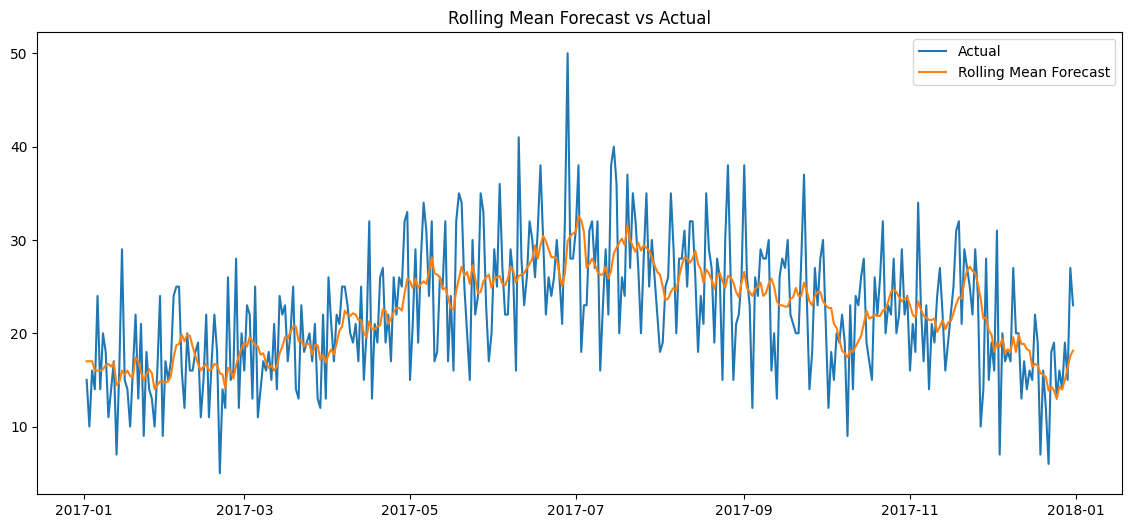

In [4]:
plt.figure(figsize=(14,6))
plt.plot(valid['date'], valid['sales'], label='Actual')
plt.plot(valid['date'], valid['rolling_forecast'], label='Rolling Mean Forecast')
plt.legend()
plt.title("Rolling Mean Forecast vs Actual")
plt.show()
